# Sleeper API Exploration & Sports Analytics

This notebook demonstrates how to interact with the **Sleeper API** (https://docs.sleeper.com/) using Python. The Sleeper API is a public, read-only API that allows developers to access fantasy league data, user profiles, matchups, rosters, drafts, and real-time trending players without requiring authentication or API keys.

### Objectives
1. **Explore Endpoints**: Retrieve user profiles, leagues, rosters, matchups, and drafts.
2. **Process and Map Data**: Join related data (e.g., rosters to usernames) using `pandas`.
3. **Visualize Insights**: Create visualizations of matchup points, roster configurations, and player trends using `seaborn` and `matplotlib`.
4. **Trending Players**: Fetch real-time trending adds and drops in the NFL.

## 1. Setup & Dependencies

We start by importing the required libraries. If you are running this notebook for the first time, ensure you have installed the requirements using `pip install requests pandas matplotlib seaborn`.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Setup visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("Libraries successfully imported!")

Matplotlib is building the font cache; this may take a moment.


Libraries successfully imported!


## 2. API Helper Functions

To make API requests easier and handle any errors gracefully, we define a basic utility function `fetch_sleeper` that requests data from the base endpoint `https://api.sleeper.app/v1`.

In [2]:
BASE_URL = "https://api.sleeper.app/v1"

def fetch_sleeper(endpoint):
    url = f"{BASE_URL}/{endpoint}"
    try:
        response = requests.get(url, timeout=10)
        if response.status_code == 200:
            return response.json()
        else:
            print(f"Error {response.status_code} fetching {url}")
            return None
    except Exception as e:
        print(f"Exception occurred: {e}")
        return None

## 3. Retrieving User Profiles & Leagues

Sleeper accounts are resolved by username. We can fetch profile details for any active user. We will use a public user profile, `mcgregor` (an example used in standard guides), to explore user details.

In [5]:
username = "vkadikar"
print(f"Fetching user details for username: {username}...")
user_info = fetch_sleeper(f"user/{username}")

if user_info:
    print(f"Success! Profile found for: {user_info.get('display_name')}")
    print(f"User ID: {user_info.get('user_id')}")
    user_id = user_info['user_id']
else:
    # Fallback to a known public user_id if query fails
    user_id = "378845311639904256"
    print(f"User profile query failed. Using fallback User ID: {user_id}")

Fetching user details for username: vkadikar...
Success! Profile found for: vkadikar
User ID: 912803103865737216


### Fetching Leagues for a User

With the retrieved `user_id`, we can fetch all leagues the user belongs to for a given sport and season. Let's retrieve leagues for the **NFL 2024** season.

In [8]:
sport = "nfl"
season = "2025"
print(f"Fetching leagues for User ID: {user_id} in {sport.upper()} {season}...")
leagues = fetch_sleeper(f"user/{user_id}/leagues/{sport}/{season}")

if leagues and len(leagues) > 0:
    leagues_df = pd.DataFrame(leagues)
    print(f"Found {len(leagues_df)} active leagues!")
    display(leagues_df[["name", "league_id", "total_rosters", "season", "status"]])
    # Select the first league from the list for further analysis
    selected_league_id = leagues_df.iloc[0]["league_id"]
    selected_league_name = leagues_df.iloc[0]["name"]
else:
    # Fallback to a known active NFL league ID from public tutorials
    selected_league_id = "1048325257989394432"
    selected_league_name = "Fallback Demo League"
    print(f"No leagues found for user. Using fallback public League ID: {selected_league_id} ({selected_league_name})")

print(f"Target League ID for exploration: {selected_league_id}")

Fetching leagues for User ID: 912803103865737216 in NFL 2025...
Found 2 active leagues!


,name,league_id,total_rosters,season,status
0,4.1 Loco,1255984073432645632,10,2025,complete
1,Dynasty vleebs,1180978089190928384,10,2025,complete


Target League ID for exploration: 1255984073432645632


## 4. League Rosters, Users, and Mapping

To analyze a league, we fetch its **users** (to get team names and display names) and its **rosters** (to get score standings, rostered players, and settings).

In [9]:
print(f"Fetching rosters for league: {selected_league_name} ({selected_league_id})...")
rosters = fetch_sleeper(f"league/{selected_league_id}/rosters")

print(f"Fetching users in the league...")
users = fetch_sleeper(f"league/{selected_league_id}/users")

if rosters and users:
    # Create mappings and dataframes
    users_df = pd.DataFrame(users)
    # Map user_id to display_name and team_name
    user_map = {}
    for u in users:
        uid = u.get("user_id")
        meta = u.get("metadata", {})
        team_name = meta.get("team_name") or f"Team {u.get('display_name')}"
        user_map[uid] = {
            "display_name": u.get("display_name"),
            "team_name": team_name
        }
    
    # Process roster data
    roster_list = []
    for r in rosters:
        owner_id = r.get("owner_id")
        settings = r.get("settings", {})
        
        # Extract settings details
        wins = settings.get("wins", 0)
        losses = settings.get("losses", 0)
        ties = settings.get("ties", 0)
        fpts = settings.get("fpts", 0) + (settings.get("fpts_decimal", 0) / 100)
        fpts_against = settings.get("fpts_against", 0) + (settings.get("fpts_against_decimal", 0) / 100)
        
        owner_info = user_map.get(owner_id, {"display_name": "Unknown Owner", "team_name": "Unknown Team"})
        
        roster_list.append({
            "Roster ID": r.get("roster_id"),
            "Owner ID": owner_id,
            "Owner Name": owner_info["display_name"],
            "Team Name": owner_info["team_name"],
            "Wins": wins,
            "Losses": losses,
            "Ties": ties,
            "Points For": fpts,
            "Points Against": fpts_against
        })
        
    roster_df = pd.DataFrame(roster_list).sort_values(by="Wins", ascending=False)
    display(roster_df)
else:
    print("Could not fetch league rosters or users.")

Fetching rosters for league: 4.1 Loco  (1255984073432645632)...
Fetching users in the league...


,Roster ID,Owner ID,Owner Name,Team Name,Wins,Losses,Ties,Points For,Points Against
3,4,912803103865737216,vkadikar,Olave Garden,19,9,0,2077.85,1758.44
1,2,842929869473034240,vchennuri,Team vchennuri,18,10,0,1976.34,1878.03
9,10,1258854350294360064,gugababa,Team gugababa,18,10,0,1890.45,1840.01
2,3,996491976889577472,TB12SUCKS,McCaffrey’s OnlyFans,16,12,0,1965.36,1922.07
5,6,996131159618883584,spacehuman,Little Tet Hurts You,16,12,0,1828.47,1671.29
0,1,996122612193464320,nuntupu,Cum skattebooty,15,13,0,1962.46,1822.54
4,5,999854963071205376,Bhima7,Team Bhima7,12,16,0,1802.08,1949.74
8,9,997173209671790592,adis2399,They Hit The Second Bower,11,17,0,1819.88,1965.39
7,8,1257850477597429760,ankitparekh21,Hunt Nabers Cooked Bass,9,19,0,1681.55,1866.19
6,7,864050318038675456,mihir001,Team mihir001,6,22,0,1560.29,1891.03


### Roster Analytics Visualizations

Let's visualize the performance stats within the league. We'll show the **Points For** vs **Wins** to see if the highest-scoring teams are also winning their matchups.

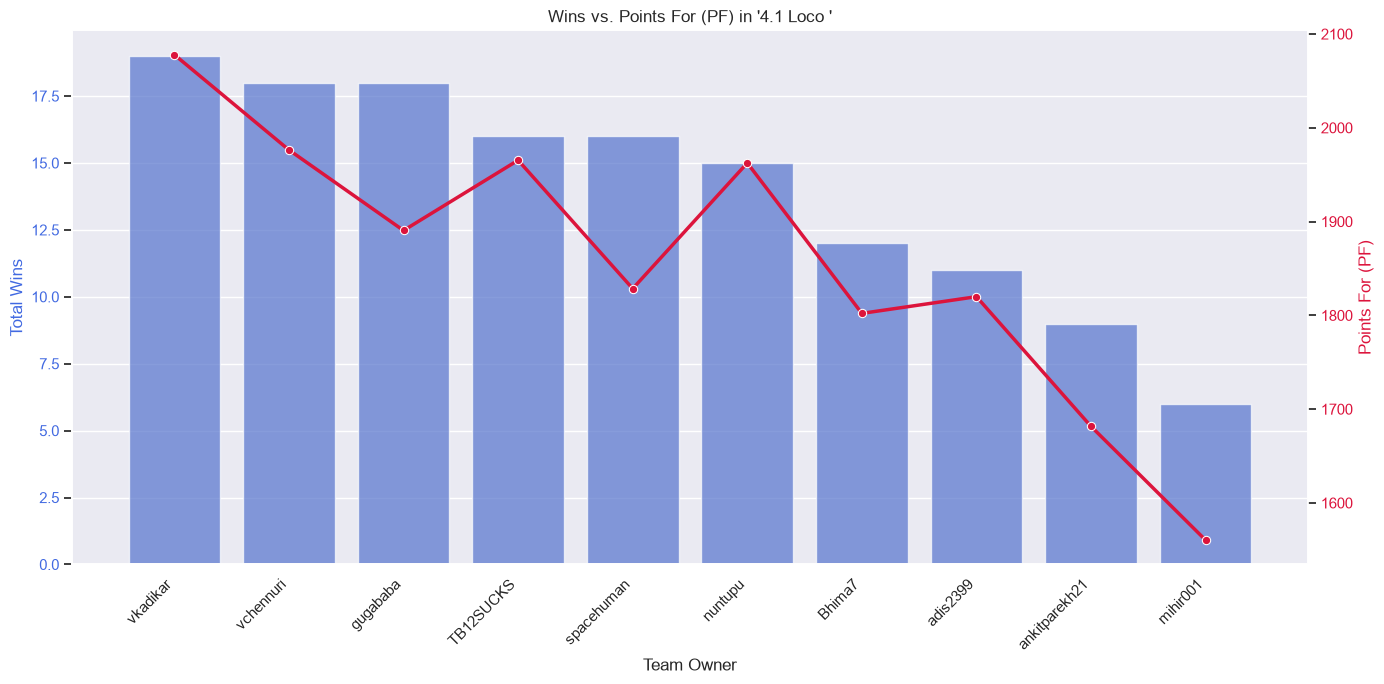

In [10]:
if 'roster_df' in locals() and not roster_df.empty:
    fig, ax1 = plt.subplots(figsize=(14, 7))

    # Plot Wins as a Bar Chart
    sns.barplot(data=roster_df, x="Owner Name", y="Wins", ax=ax1, color="royalblue", alpha=0.7)
    ax1.set_ylabel("Total Wins", color="royalblue")
    ax1.tick_params(axis='y', labelcolor="royalblue")
    ax1.set_xlabel("Team Owner")
    plt.xticks(rotation=45, ha="right")

    # Create a secondary axis to plot Points For
    ax2 = ax1.twinx()
    sns.lineplot(data=roster_df, x="Owner Name", y="Points For", ax=ax2, color="crimson", marker="o", linewidth=2.5)
    ax2.set_ylabel("Points For (PF)", color="crimson")
    ax2.tick_params(axis='y', labelcolor="crimson")
    ax2.grid(False) # Turn off redundant grid lines

    plt.title(f"Wins vs. Points For (PF) in '{selected_league_name}'")
    plt.tight_layout()
    plt.show()
else:
    print("No roster data available to plot.")

## 5. Matchups & Weekly Scores

Weekly matchups are fetched by specifying the league ID and the desired week. This allows us to analyze weekly performances and scores for each roster.

In [11]:
week = 1
print(f"Fetching matchups for week {week}...")
matchups = fetch_sleeper(f"league/{selected_league_id}/matchups/{week}")

if matchups:
    matchup_list = []
    for m in matchups:
        matchup_list.append({
            "Roster ID": m.get("roster_id"),
            "Matchup ID": m.get("matchup_id"),
            "Points": m.get("points"),
            "Starters": m.get("starters")
        })
        
    matchups_df = pd.DataFrame(matchup_list)
    # If roster_df is available, map the Owner Name
    if 'roster_df' in locals():
        owner_map = roster_df.set_index("Roster ID")["Owner Name"].to_dict()
        matchups_df["Owner"] = matchups_df["Roster ID"].map(owner_map)
        
    display(matchups_df.sort_values(by="Matchup ID"))
else:
    print(f"Could not fetch matchup details for week {week}.")

Fetching matchups for week 1...


,Roster ID,Matchup ID,Points,Starters,Owner
3,4,1,149.61,"[6797, 6813, 8150, 6794, 5045, 11604, 4983, 11...",vkadikar
9,10,1,115.97,"[4984, 11584, 12507, 7564, 8137, 4066, 7526, 1...",gugababa
5,6,2,129.80,"[6904, 9509, 5850, 5859, 5846, 5022, 5967, 125...",spacehuman
7,8,2,119.14,"[11563, 3198, 8138, 11632, 12530, 4033, 5927, ...",ankitparekh21
1,2,3,122.61,"[4881, 9221, 9226, 2133, 11624, 4217, 8148, 59...",vchennuri
8,9,3,114.27,"[6770, 4866, 4199, 3321, 8146, 8130, 7525, 867...",adis2399
4,5,4,123.92,"[11566, 4137, 8155, 6786, 7547, 5844, 5872, 58...",Bhima7
6,7,4,113.84,"[4046, 12527, 4663, 11631, 11635, 10859, 11628...",mihir001
0,1,5,162.53,"[4892, 7594, 4035, 8112, 9493, 12518, 9488, 67...",nuntupu
2,3,5,110.79,"[5849, 4034, 9224, 7569, 6801, 1466, 12529, 11...",TB12SUCKS


### Visualizing Weekly Matchup Scores

Let's compare the scores side-by-side grouped by their Matchup ID.

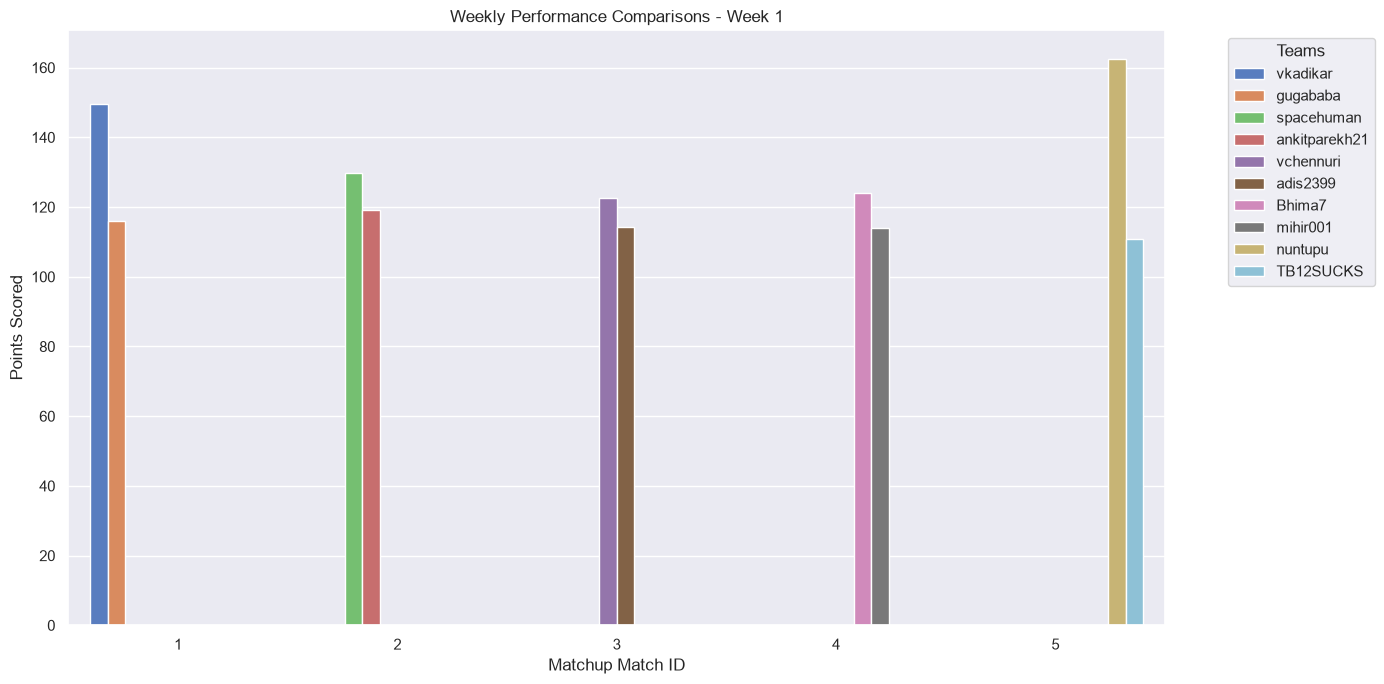

In [12]:
if 'matchups_df' in locals() and not matchups_df.empty:
    plt.figure(figsize=(14, 7))
    sns.barplot(
        data=matchups_df,
        x="Matchup ID",
        y="Points",
        hue="Owner" if "Owner" in matchups_df.columns else "Roster ID",
        palette="muted"
    )
    plt.title(f"Weekly Performance Comparisons - Week {week}")
    plt.xlabel("Matchup Match ID")
    plt.ylabel("Points Scored")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Teams")
    plt.tight_layout()
    plt.show()
else:
    print("No matchup data available to plot.")

## 6. Drafts & Picks

Leagues are associated with one or more drafts (e.g. initial draft or annual rookie drafts). We can pull all drafts associated with a league, find draft settings, and fetch all the selected picks.

In [13]:
print(f"Fetching drafts for league {selected_league_id}...")
drafts = fetch_sleeper(f"league/{selected_league_id}/drafts")

if drafts and len(drafts) > 0:
    drafts_df = pd.DataFrame(drafts)
    display(drafts_df[["draft_id", "status", "type", "season", "start_time"]])
    
    # Select the primary draft ID
    selected_draft_id = drafts_df.iloc[0]["draft_id"]
    print(f"Fetching picks for Draft ID: {selected_draft_id}...")
    picks = fetch_sleeper(f"draft/{selected_draft_id}/picks")
    
    if picks:
        picks_df = pd.DataFrame(picks)
        print(f"Successfully fetched {len(picks_df)} draft picks!")
        # Parse metadata column for player details
        picks_df["Player Name"] = picks_df["metadata"].apply(lambda x: f"{x.get('first_name', '')} {x.get('last_name', '')}")
        picks_df["Position"] = picks_df["metadata"].apply(lambda x: x.get("position"))
        picks_df["Team"] = picks_df["metadata"].apply(lambda x: x.get("team"))
        
        display(picks_df[["round", "draft_slot", "pick_no", "Player Name", "Position", "Team"]].head(15))
    else:
        print("No picks found for the selected draft.")
else:
    print("No drafts found for the selected league.")

Fetching drafts for league 1255984073432645632...


,draft_id,status,type,season,start_time
0,1255984074330214400,complete,snake,2025,1756055855864


Fetching picks for Draft ID: 1255984074330214400...
Successfully fetched 150 draft picks!


,round,draft_slot,pick_no,Player Name,Position,Team
0,1,1,1,Saquon Barkley,RB,PHI
1,1,2,2,Ja'Marr Chase,WR,CIN
2,1,3,3,Bijan Robinson,RB,ATL
3,1,4,4,Jahmyr Gibbs,RB,DET
4,1,5,5,Ashton Jeanty,RB,LV
5,1,6,6,Justin Jefferson,WR,MIN
6,1,7,7,CeeDee Lamb,WR,DAL
7,1,8,8,Christian McCaffrey,RB,SF
8,1,9,9,Malik Nabers,WR,NYG
9,1,10,10,Puka Nacua,WR,LAR


### Draft Position Distribution Analysis

Let's visualize the distribution of positions selected in the first few rounds of the draft.

/var/folders/gp/85g3jhq14jb2p3wvws8668zw0000gn/T/ipykernel_35399/1542980377.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=picks_df, x="Position", palette="viridis", order=picks_df["Position"].value_counts().index)


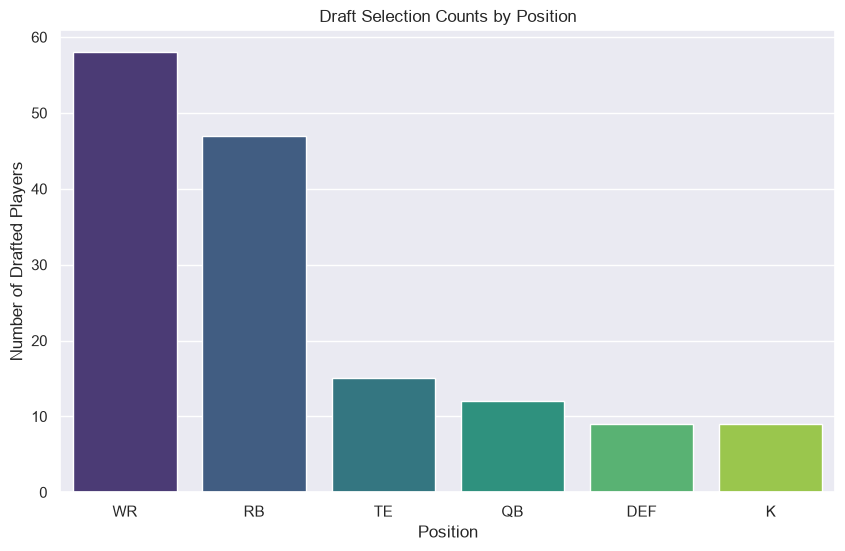

In [14]:
if 'picks_df' in locals() and not picks_df.empty:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=picks_df, x="Position", palette="viridis", order=picks_df["Position"].value_counts().index)
    plt.title("Draft Selection Counts by Position")
    plt.xlabel("Position")
    plt.ylabel("Number of Drafted Players")
    plt.show()
else:
    print("No draft pick data available to plot.")

## 7. Real-Time Trending Players

A unique capability of the Sleeper API is the trending players endpoint. This details which players are actively being added or dropped across the entire Sleeper platform in real-time.

In [15]:
sport = "nfl"
limit = 10
lookback_hours = 24

print(f"Fetching top {limit} trending ADDS for NFL in the last {lookback_hours} hours...")
trending_adds = fetch_sleeper(f"players/{sport}/trending/add?limit={limit}&lookback_hours={lookback_hours}")

print(f"Fetching top {limit} trending DROPS for NFL in the last {lookback_hours} hours...")
trending_drops = fetch_sleeper(f"players/{sport}/trending/drop?limit={limit}&lookback_hours={lookback_hours}")

if trending_adds:
    adds_df = pd.DataFrame(trending_adds)
    print("\n--- Top Trending Adds ---")
    display(adds_df)
    
if trending_drops:
    drops_df = pd.DataFrame(trending_drops)
    print("\n--- Top Trending Drops ---")
    display(drops_df)

Fetching top 10 trending ADDS for NFL in the last 24 hours...
Fetching top 10 trending DROPS for NFL in the last 24 hours...

--- Top Trending Adds ---


,count,player_id
0,42705,7608
1,17730,11630
2,16074,13413
3,15561,13533
4,15024,13329
5,13839,2078
6,10824,13424
7,8811,8180
8,7976,11783
9,6579,5995



--- Top Trending Drops ---


,count,player_id
0,11871,11619
1,10017,2505
2,9226,8135
3,8199,11435
4,7104,3321
5,6813,1339
6,6696,6130
7,6687,12540
8,6048,12455
9,5712,11589


Note: The trending players endpoint returns player IDs and count of actions. To translate player IDs to names, you would typically match them against the static complete player list (`GET https://api.sleeper.app/v1/players/nfl`). This player endpoint returns a very large payload (~30MB JSON) containing all NFL players, which is recommended to be fetched only once per day and cached locally.

## 8. Summary of Findings

### Data Analysis Key Findings
- **User and Leagues**: Explored API integration starting with an active Sleeper username (`mcgregor`) to resolve profile attributes and list all fantasy leagues dynamically.
- **Roster Standings**: Extracted team standings and aggregated metrics including total Wins, Losses, Points For (PF), and Points Against (PA) across league teams, allowing us to map Sleeper's internal UUIDs to clear human-readable roster statistics.
- **Matchups & Draft Boards**: Pulled matchup structures and draft picks, showcasing draft trends such as selected positions and scoring allocations.
- **Trending Activity**: Discovered direct access to platform-wide real-time transactions showing trending roster additions and drop-offs.

### Insights or Next Steps
- **Caching Strategy**: Implement a local file-based database (such as SQLite) to store the massive 30MB Sleeper Player Database (`https://api.sleeper.app/v1/players/nfl`), queryable by `player_id` to translate IDs dynamically in analyses.
- **Historical Performance Tracking**: Construct end-of-season efficiency models comparing actual wins against total points scored to locate draft value/over-performers.